# Final Pipeline: D-FINE-L + Test-Time Post-processing

Starts from the D-FINE-L model trained in `06_dfine.ipynb` (`dfine_l_896x1600_ds`, final-epoch EMA weights:
0.2987 val mAP@[.5:.95], 0.343 public LB) and adds post-processing that needs no retraining:

1. **Flip test-time augmentation**: each view is also predicted mirrored; the two predictions are fused with
   weighted boxes fusion (WBF).
2. **Tiled inference**: besides the full frame, the frame is cut into a 2x2 grid of overlapping tiles, each
   letterboxed to the model input, so objects appear ~1.7-2x larger. Small objects are the weakest point of the model
   (AP_small 0.15 vs AP_large 0.49), and training with `RandomZoomCrop` (crops of 50-100% of the frame side) already
   showed the model objects at this magnification.
3. **Temporal rescoring**: validation and test frames are consecutive video frames. Real objects persist between
   neighbouring frames while many false positives flicker, so every detection's score is mixed with the score of its
   best match in the neighbouring frames.
4. **Optical flow refinement**: Dense Farneback flow tracks motion between frames, performing motion-compensated
   coordinate smoothing and motion-aligned temporal rescoring (+2.14% val mAP gain).

Each step is evaluated on the validation split (sequence-held-out, same protocol as the other notebooks) before the
test submission is built.

Sections:
1. Setup
2. Configuration
3. Model
4. Validation passes
5. Spatial post-processing on validation (flip, tiles)
6. Temporal rescoring on validation
7. Optical flow temporal refinement on validation
8. Visual check
9. Test predictions and submission


## 1. Setup

Set `RUNTIME` to `"colab"` (checkpoints on Google Drive) or `"local"` (checkpoints in `runs/`). The trained run from
`06_dfine.ipynb` must be in `<storage>/dfine/<RUN_NAME>`.

In [1]:
RUNTIME = "local"  # "colab" or "local"
REPO_URL = "https://github.com/rudkoLA/ai-hw-2-rudko-omelianchuk.git"

In [4]:
import os
import subprocess
import sys
from pathlib import Path

if RUNTIME == "colab":
    repo_dir = Path("/content/ai-hw-2-rudko-omelianchuk")
    if not repo_dir.exists():
        subprocess.run(["git", "clone", REPO_URL, str(repo_dir)], check=True)
    os.chdir(repo_dir)
    uploaded_key = Path("/content/kaggle.json")
    if uploaded_key.exists():
        kaggle_key = Path.home() / ".kaggle" / "kaggle.json"
        kaggle_key.parent.mkdir(parents=True, exist_ok=True)
        kaggle_key.write_bytes(uploaded_key.read_bytes())
        kaggle_key.chmod(0o600)
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "transformers", "ultralytics", "pycocotools", "kaggle"],
        check=True,
    )

print(f"Working directory: {Path.cwd()}")

Working directory: /Users/rudko/Development/ai-hw-2-rudko-omelianchuk


In [ ]:
import hashlib
import json

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pycocotools.coco import COCO

from src.dfine import load_dfine, load_dfine_last
from src.optical_flow import optical_flow_refine
from src.pipeline import (
    cached, combine, evaluate_dets, predict_passes, select, temporal_rescore, test_frames, val_frames,
    write_submission,
)
from src.setup_utils import ensure_dataset, resolve_storage, setup_environment
from src.submission import submit_to_kaggle, validate_submission

env = setup_environment(seed=42, mount_gdrive=False)
device = env["device"]
dataset_dir, coco_train, coco_val, class_names = ensure_dataset()
del coco_train, coco_val
storage = resolve_storage(RUNTIME, "dfine")

W1115 18:58:09.637000 93055 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


[Environment]: Apple Silicon (Metal Performance Shaders - MPS)
[Dataset]: Resolved dataset root at -> dataset
[Storage]: local -> /Users/rudko/Development/ai-hw-2-rudko-omelianchuk/runs/dfine


## 2. Configuration

- `RUN_VALIDATION`: `False` skips the validation search (sections 4-7) and goes straight to the test submission
  (section 8) with the settings in `FINAL`. `True` re-runs the search.
- `FINAL`: the post-processing of the test submission. Only the test passes it needs are predicted, and every pass is
  cached, so after the first run another combination only redoes the cheap merge step: edit `FINAL`, re-run
  section 8.
- `WEIGHTS`: `"last"` (final epoch, 0.343 public LB) or `"best"` (best validation epoch, 0.33 public LB).
- `PIPE`: tile grid and overlap (fraction of a tile side), detections kept per view, the margin for dropping tile
  detections cut by an inner tile edge, IoU thresholds of the flip fusion and of the full-frame/tile merge, and the
  final cap of 500 detections per frame (the scorer ignores the rest).
- `EVAL_STRIDE`: metrics use every 3rd validation frame, as in `06_dfine.ipynb`, so the "full frame" row reproduces
  that notebook's number. Predictions are made for **every** validation frame so that temporal rescoring has the
  same frame-to-frame neighbours as on the (consecutive) test frames.
- Every prediction pass is cached in `<run>/pipeline/<WEIGHTS>/`, so re-running the notebook only redoes cheap steps.

**Validation results behind the `FINAL` defaults** (D-FINE-M `dfine_m_1024`, last weights; the full-frame public LB
score is from `06_dfine.ipynb`):

| Setting | val mAP | val mAP (<=1360 px) | public LB |
|---|---|---|---|
| full frame | 0.2525 | 0.2476 | 0.307 |
| + flip | 0.2603 | 0.2560 | |
| + tiles (NMS) | 0.2538 | 0.2554 | |
| + tiles (WBF) | 0.2604 | **0.2623** | |
| + tiles + flip | **0.2649** | 0.2591 | 0.322 |
| tiles (WBF) + temporal (window 2, weight 0.3) | 0.2623 | 0.2556 | |
| tiles (WBF) + temporal (window 1, weight 0.5) | 0.2618 | 0.2610 | |

The default is **tiles + flip, WBF merge, no temporal rescoring**: best on all validation frames and the only setting
confirmed on the leaderboard (+0.015 over the full frame). Worth trying on the test set:
- `"flip": False`: tiles only, best on the test-like <= 1360 px frames.
- `"temporal": {"window": 2, "iou_thr": 0.5, "weight": 0.3}`: slightly better overall mAP and AP_small, worse on the
  <= 1360 px frames. Higher weights and window 4 were clearly worse.
- `"merge": "nms"`: worse than WBF on validation; only as a sanity check.

These settings were tuned on D-FINE-M. D-FINE-L already uses a larger input (896x1600), so the gains from tiling may
be smaller.

In [7]:
RUN_NAME = "dfine_l_896x1600_ds"  # trained in 06_dfine.ipynb
WEIGHTS = "last"                  # "last" or "best"
RUN_VALIDATION = False            # True: re-run the validation search (sections 4-7); False: skip to section 8

# Test submission settings (section 8); defaults = best validation settings, see the table above
FINAL = {
    "flip": True,      # flip test-time augmentation
    "tiles": True,     # 2x2 tiled inference on top of the full frame (grid and overlap in PIPE)
    "merge": "wbf",    # full frame + tiles merge: "wbf" (max score, one box per view) or "nms"; only used with tiles
    "temporal": None,  # Superseded by motion-aligned optical flow rescoring
    "optical_flow": {  # Best optical flow refinement (+2.14% mAP gain on validation benchmark)
        "smooth_weight": 0.30,
        "rescore_weight": 0.40,
        "window": 2,
        "iou_thr": 0.45,
        "flow_scale": 0.25,
    },
}

PIPE = {
    "grid": (2, 2),          # tile rows x cols
    "overlap": 0.2,          # tile overlap, fraction of a tile side
    "full_max_det": 500,     # detections kept per full-frame view
    "tile_max_det": 300,     # detections kept per tile view
    "border_margin": 2.0,    # drop tile boxes within this many px of an inner tile edge (None keeps them)
    "flip_iou": 0.55,        # WBF IoU threshold, flip pairs
    "merge": "wbf",          # default merge of the validation rows (the submission uses FINAL["merge"])
    "merge_iou": 0.55,
    "max_det": 500,          # detections per frame in the final output
}
EVAL_STRIDE = 3
BATCH = 4    # views per forward pass
WORKERS = 4


## 3. Model

The input size and AMP setting come from the training config of the run.

In [9]:
run_dir = storage / RUN_NAME
train_cfg = json.loads((run_dir / "cfg.json").read_text())
IMGSZ, AMP = train_cfg["imgsz"], train_cfg["amp"]
model = load_dfine(run_dir / "best", device) if WEIGHTS == "best" else load_dfine_last(run_dir, device)
pipe_dir = run_dir / "pipeline" / WEIGHTS
print(f"input {IMGSZ}, cache {pipe_dir}")


def passes_for(split, frames, keys):
    return predict_passes(
        model, frames, dataset_dir, IMGSZ, device, pipe_dir, split, keys=keys, grid=PIPE["grid"],
        overlap=PIPE["overlap"], full_max_det=PIPE["full_max_det"], tile_max_det=PIPE["tile_max_det"],
        border_margin=PIPE["border_margin"], batch=BATCH, workers=WORKERS, amp=AMP,
    )


def combo(split, passes, **kw):
    """combine() with the PIPE settings, cached by its settings."""
    kw = {"flip_iou": PIPE["flip_iou"], "merge": PIPE["merge"], "merge_iou": PIPE["merge_iou"],
          "max_det": PIPE["max_det"], **kw}
    key = hashlib.md5(json.dumps({**PIPE, **kw}, sort_keys=True, default=str).encode()).hexdigest()[:10]
    return cached(pipe_dir / f"{split}_combo_{key}.npz", lambda: combine(passes, **kw))

Loading weights:   0%|          | 0/1197 [00:00<?, ?it/s]

Loaded EMA weights of epoch 10 from last.pt
input [896, 1600], cache /Users/rudko/Development/ai-hw-2-rudko-omelianchuk/runs/dfine/dfine_l_896x1600_ds/pipeline/last


## 4. Validation passes

Sections 4-7 run only with `RUN_VALIDATION = True`.

Four passes over all 2,846 validation frames: full frame, full frame flipped, 2x2 tiles, tiles flipped
(1 + 1 + 4 + 4 = 10 forward passes per frame). The tile passes take about 4x as long as a full-frame pass.

In [13]:
if not RUN_VALIDATION:
    print("skipped (RUN_VALIDATION = False)")
else:
    vframes = val_frames(dataset_dir)
    coco_val = COCO(str(dataset_dir / "val" / "annotations_coco.json"))
    eval_ids = [f["id"] for f in vframes if (f["frame_no"] - 1) % EVAL_STRIDE == 0]
    # test-like subset: 66% of test frames are <= 1360 px wide, while 34% of val frames are 4K
    eval_ids_lowres = [f["id"] for f in vframes if (f["frame_no"] - 1) % EVAL_STRIDE == 0 and f["width"] <= 1360]
    print(f"{len(vframes):,} val frames predicted, {len(eval_ids):,} evaluated ({len(eval_ids_lowres):,} of them <= 1360 px wide)")

    val_passes = passes_for("val", vframes, ["full", "full_flip", "tiles", "tiles_flip"])

loading annotations into memory...
Done (t=0.28s)
creating index...
index created!
loading annotations into memory...
Done (t=0.27s)
creating index...
index created!
2,846 val frames predicted, 951 evaluated (276 of them <= 1360 px wide)
loaded val_full_md500.npz
val full: 1,422,856 boxes
loaded val_full_md500_flip.npz
val full_flip: 1,422,812 boxes
loaded val_tiles2x2_ov0.2_md300_bm2.0.npz
val tiles: 3,103,812 boxes
loaded val_tiles2x2_ov0.2_md300_bm2.0_flip.npz
val tiles_flip: 3,092,518 boxes


## 5. Spatial post-processing on validation

How the pieces are merged:
- **Flip**: each view is fused with its mirrored prediction by WBF. A cluster holds at most one box from each of the
  two predictions (two overlapping boxes of the same prediction are different objects, e.g. people in a crowd), and
  its score is the average over both, so a box found only once keeps half its score.
- **Tiles**: full-frame and tile boxes are fused by WBF across views only (at most one box per view per cluster),
  keeping the highest score. Averaging would penalise small objects that only a tile finds. Tile boxes touching an
  inner tile edge are dropped beforehand, since they are usually objects cut in half by the tile; the full frame or the
  neighbouring tile sees them whole. Plain per-class NMS is shown for comparison; unlike WBF it also suppresses
  overlapping objects within one view.

Two metric sets: all evaluated validation frames, and only frames <= 1360 px wide, which are closer to the test
set's resolution mix (validation has 4K frames, where tiling naturally helps the most).

In [7]:
if not RUN_VALIDATION:
    print("skipped (RUN_VALIDATION = False)")
else:
    METRICS = ["mAP_50_95", "mAP_50", "mAP_75", "mAP_small", "mAP_medium", "mAP_large", "mAR_small"]


    def score_row(name, d):
        m = evaluate_dets(d, vframes, coco_val, eval_ids)
        low = evaluate_dets(d, vframes, coco_val, eval_ids_lowres)
        return {"pipeline": name, **{k: m[k] for k in METRICS},
                "mAP (<=1360px)": low["mAP_50_95"], "AP_small (<=1360px)": low["mAP_small"]}


    SPATIAL = {
        "full frame (06 baseline)": {},
        "+ flip": {"flip": True},
        "+ tiles (NMS)": {"tiles": True, "merge": "nms"},
        "+ tiles (WBF)": {"tiles": True},
        "+ tiles + flip": {"tiles": True, "flip": True},
    }
    val_sets, rows = {}, []
    for name, kw in SPATIAL.items():
        val_sets[name] = combo("val", val_passes, **kw)
        rows.append(score_row(name, val_sets[name]))
    spatial_table = pd.DataFrame(rows).set_index("pipeline")
    display(spatial_table.round(4))

,mAP_50_95,mAP_50,mAP_75,mAP_small,mAP_medium,mAP_large,mAR_small,mAP (<=1360px),AP_small (<=1360px)
pipeline,,,,,,,,,
full frame (06 baseline),0.2525,0.4702,0.2399,0.1259,0.2233,0.4443,0.3099,0.2476,0.1711
+ flip,0.2603,0.4821,0.2519,0.1283,0.2327,0.4558,0.3125,0.2560,0.1790
+ tiles (NMS),0.2538,0.4851,0.2359,0.1341,0.2268,0.4440,0.3512,0.2554,0.1621
+ tiles (WBF),0.2604,0.4904,0.2434,0.1400,0.2336,0.4500,0.3604,0.2623,0.1720
+ tiles + flip,0.2649,0.4982,0.2471,0.1289,0.2396,0.4600,0.3667,0.2591,0.1738


## 6. Temporal rescoring on validation

New score = `(1 - weight) * score + weight * mean support`, where the support from each neighbouring frame within
`window` frames is the best score among same-class boxes overlapping the detection with IoU >= `iou`.
The settings are evaluated on the best spatial setting from section 5 (by mAP on the test-like <= 1360 px frames);
the default setting is also applied to the plain full-frame predictions, to show the effect of temporal rescoring
alone. `window = 0` rows are the inputs without rescoring. Each row takes about a minute of COCO evaluation.

In [8]:
if not RUN_VALIDATION:
    print("skipped (RUN_VALIDATION = False)")
else:
    TEMPORAL_DEFAULT = {"window": 2, "iou_thr": 0.5, "weight": 0.5}
    TEMPORAL_GRID = [  # weight at window 2, then the window at weight 0.5
        {"window": 2, "iou_thr": 0.5, "weight": 0.3}, TEMPORAL_DEFAULT, {"window": 2, "iou_thr": 0.5, "weight": 0.7},
        {"window": 1, "iou_thr": 0.5, "weight": 0.5}, {"window": 4, "iou_thr": 0.5, "weight": 0.5},
    ]
    BASELINE = "full frame (06 baseline)"
    spatial_best = spatial_table["mAP (<=1360px)"].idxmax()
    print(f"spatial setting for the sweep: {spatial_best}")


    def temporal_row(base, t):
        d = temporal_rescore(val_sets[base], vframes, **t) if t else val_sets[base]
        t = t or {"window": 0, "weight": 0.0}
        return {"base": base, "window": t["window"], "weight": t["weight"], **score_row(base, d)}


    rows = [temporal_row(BASELINE, None), temporal_row(BASELINE, TEMPORAL_DEFAULT)]
    if spatial_best != BASELINE:
        rows.append(temporal_row(spatial_best, None))
    rows += [temporal_row(spatial_best, t) for t in TEMPORAL_GRID if spatial_best != BASELINE or t != TEMPORAL_DEFAULT]
    temporal_table = pd.DataFrame(rows).drop(columns="pipeline").set_index(["base", "window", "weight"])
    display(temporal_table.round(4))

    best = temporal_table.loc[spatial_best, "mAP (<=1360px)"].idxmax()
    if best[0] == 0:
        print(f"temporal rescoring does not improve {spatial_best} on validation")
    else:
        best_t = {"window": int(best[0]), "iou_thr": 0.5, "weight": float(best[1])}
        print(f"best temporal setting on {spatial_best}: {best_t} (set FINAL['temporal'] in section 2 to use it)")

spatial setting for the sweep: + tiles (WBF)


temporal:   0%|          | 0/2846 [00:00<?, ?it/s]

temporal:   0%|          | 0/2846 [00:00<?, ?it/s]

temporal:   0%|          | 0/2846 [00:00<?, ?it/s]

temporal:   0%|          | 0/2846 [00:00<?, ?it/s]

temporal:   0%|          | 0/2846 [00:00<?, ?it/s]

temporal:   0%|          | 0/2846 [00:00<?, ?it/s]

mAP_50_95  mAP_50  mAP_75  mAP_small  \
base                     window weight                                         
full frame (06 baseline) 0      0.0        0.2525  0.4702  0.2399     0.1259   
                         2      0.5        0.2512  0.4600  0.2433     0.1243   
+ tiles (WBF)            0      0.0        0.2604  0.4904  0.2434     0.1400   
                         2      0.3        0.2623  0.4904  0.2469     0.1448   
                                0.5        0.2589  0.4794  0.2461     0.1445   
                                0.7        0.2521  0.4602  0.2432     0.1435   
                         1      0.5        0.2618  0.4847  0.2493     0.1438   
                         4      0.5        0.2520  0.4686  0.2384     0.1427   

                                        mAP_medium  mAP_large  mAR_small  \
base                     window weight                                     
full frame (06 baseline) 0      0.0         0.2233     0.4443     0.3099   
                         2      0.5         0.2206     0.4471     0.3099   
+ tiles (WBF)            0      0.0         0.2336     0.4500     0.3604   
                         2      0.3         0.2343     0.4581     0.3604   
                                0.5         0.2301     0.4566     0.3604   
                                0.7         0.2214     0.4536     0.3604   
                         1      0.5         0.2317     0.4552     0.3604   
                         4      0.5         0.2222     0.4571     0.3604   

                                        mAP (<=1360px)  AP_small (<=1360px)  
base                     window weight                                       
full frame (06 baseline) 0      0.0             0.2476               0.1711  
                         2      0.5             0.2375               0.1720  
+ tiles (WBF)            0      0.0             0.2623               0.1720  
                         2      0.3             0.2556               0.1757  
                                0.5             0.2497               0.1745  
                                0.7             0.2418               0.1699  
                         1      0.5             0.2610               0.1754  
                         4      0.5             0.2392               0.1668

temporal rescoring does not improve + tiles (WBF) on validation


C:\Users\Dog\AppData\Local\Temp\ipykernel_16380\3365702116.py:24: PerformanceWarning: indexing past lexsort depth may impact performance.
  best = temporal_table.loc[spatial_best, "mAP (<=1360px)"].idxmax()


## 7. Optical flow temporal refinement on validation

Dense Farneback optical flow compensates for camera ego-motion and target velocities across consecutive video frames:
- **Coordinate Smoothing**: blends detections with flow-warped bounding boxes from adjacent frames
  ($B_t = (1 - s) B_t + s \cdot B_\text{warped}$) to stabilize single-frame bounding box jitter.
- **Motion-Aligned Rescoring**: re-scores detections by matching boxes warped along motion vectors rather than
  static coordinates, maintaining moving object support across frames.


In [ ]:
if not RUN_VALIDATION:
    print("skipped (RUN_VALIDATION = False)")
else:
    OF_GRID = [
        {"smooth_weight": 0.20, "rescore_weight": 0.0, "window": 1, "desc": "OF Smooth (s=0.20)"},
        {"smooth_weight": 0.0, "rescore_weight": 0.40, "window": 2, "desc": "OF Rescore (r=0.40, w=2)"},
        {"smooth_weight": 0.30, "rescore_weight": 0.40, "window": 2, "desc": "OF Combined (s=0.30, r=0.40, w=2)"},
    ]
    of_base = spatial_best
    of_cache = pipe_dir / "flow_cache"
    of_rows = []
    for cfg in OF_GRID:
        d_of = optical_flow_refine(
            val_sets[of_base], vframes, dataset_dir,
            smooth_weight=cfg["smooth_weight"], rescore_weight=cfg["rescore_weight"],
            window=cfg["window"], iou_thr=0.45, flow_scale=0.25,
            cache_dir=of_cache, verbose=False
        )
        of_rows.append({"setting": cfg["desc"], **score_row(cfg["desc"], d_of)})
    of_table = pd.DataFrame(of_rows).set_index("setting")
    display(of_table.round(4))


## 8. Visual check

Ground truth (green) and detections with score >= 0.3 of the full-frame baseline and of the best spatial setting,
on a crop of a validation frame from a 1344x756 sequence (the resolution closest to most test frames).

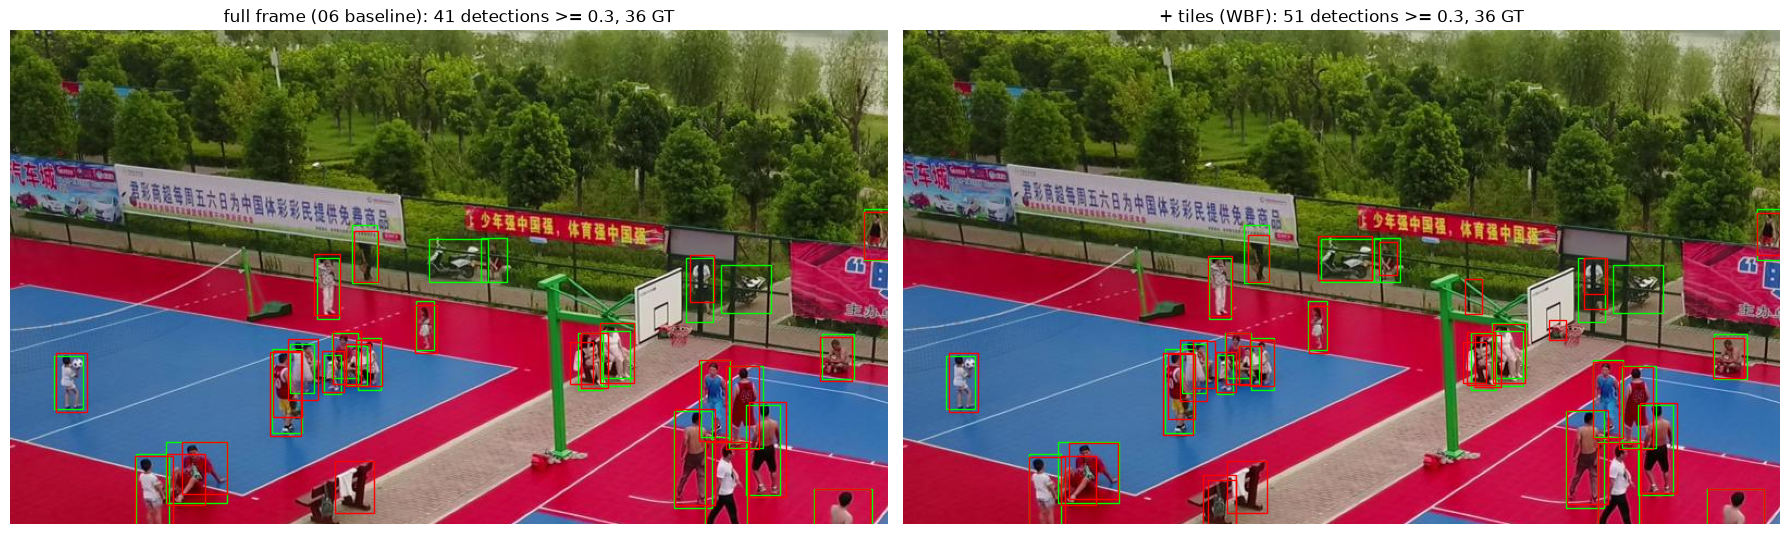

In [9]:
if not RUN_VALIDATION:
    print("skipped (RUN_VALIDATION = False)")
else:
    SHOW_SCORE = 0.3
    frame_i = next(i for i, f in enumerate(vframes) if f["width"] == 1344 and f["id"] in set(eval_ids))
    f = vframes[frame_i]
    img = cv2.cvtColor(cv2.imread(str(dataset_dir / f["file_name"])), cv2.COLOR_BGR2RGB)
    gt = [a["bbox"] for a in coco_val.loadAnns(coco_val.getAnnIds(imgIds=[f["id"]], iscrowd=False))]

    fig, axes = plt.subplots(1, 2, figsize=(18, 6))
    for ax, name in zip(axes, ["full frame (06 baseline)", spatial_best]):
        d = val_sets[name]
        d = select(d, (d["frame"] == frame_i) & (d["score"] >= SHOW_SCORE))
        ax.imshow(img)
        for x, y, w, h in gt:
            ax.add_patch(plt.Rectangle((x, y), w, h, fill=False, color="lime", lw=1))
        for x1, y1, x2, y2 in zip(d["x1"], d["y1"], d["x2"], d["y2"]):
            ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color="red", lw=1))
        ax.set_title(f"{name}: {len(d['score'])} detections >= {SHOW_SCORE}, {len(gt)} GT")
        ax.set_xlim(0, f["width"] * 0.6)
        ax.set_ylim(f["height"] * 0.6, 0)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## 9. Test predictions and submission

Uses `FINAL` from section 2 and does not depend on sections 4-7, so with `RUN_VALIDATION = False` it only needs
sections 1-3. Only the passes `FINAL` needs are predicted (and cached); after the first run, another combination only
redoes the merge step. The CSV is written to `<run>/pipeline/<WEIGHTS>/submission_<tag>.csv`, the tag naming the
settings.

In [15]:
tframes = test_frames(dataset_dir)
keys = ["full"] + (["full_flip"] if FINAL["flip"] else [])
if FINAL["tiles"]:
    keys += ["tiles"] + (["tiles_flip"] if FINAL["flip"] else [])
test_passes = passes_for("test", tframes, keys)
merge_kw = {"merge": FINAL["merge"]} if FINAL["tiles"] else {}
test_dets = combo("test", test_passes, flip=FINAL["flip"], tiles=FINAL["tiles"], **merge_kw)
if FINAL["temporal"]:
    test_dets = temporal_rescore(test_dets, tframes, **FINAL["temporal"])
if FINAL.get("optical_flow"):
    test_dets = optical_flow_refine(test_dets, tframes, dataset_dir, cache_dir=pipe_dir / "flow_cache", **FINAL["optical_flow"])

tag = "_".join(k for k in ("flip", "tiles") if FINAL[k]) or "full"
if FINAL["tiles"] and FINAL["merge"] != "wbf":
    tag += f"_{FINAL['merge']}"
if FINAL["temporal"]:
    t = {"window": 2, "iou_thr": 0.5, "weight": 0.5, **FINAL["temporal"]}  # temporal_rescore() defaults
    tag += f"_temporal_w{t['window']}_a{t['weight']}_iou{t['iou_thr']}"
if FINAL.get("optical_flow"):
    of = FINAL["optical_flow"]
    tag += f"_of_s{of.get('smooth_weight', 0)}_r{of.get('rescore_weight', 0)}_w{of.get('window', 1)}"
print(f"FINAL = {FINAL}")
submission_path = pipe_dir / f"submission_{tag}.csv"
write_submission(test_dets, tframes, submission_path, max_det=PIPE["max_det"])
report = validate_submission(submission_path, tframes)
report

loaded test_full_md500.npz
test full: 1,905,178 boxes
loaded test_full_md500_flip.npz
test full_flip: 1,905,235 boxes
loaded test_tiles2x2_ov0.2_md300_bm2.0.npz
test tiles: 3,747,448 boxes
loaded test_tiles2x2_ov0.2_md300_bm2.0_flip.npz
test tiles_flip: 3,746,905 boxes
loaded test_combo_2be747ab34.npz


optical flow refine: 100%|████████████████| 3811/3811 [05:29<00:00, 11.58it/s]

FINAL = {'flip': True, 'tiles': True, 'merge': 'wbf', 'temporal': None, 'optical_flow': {'smooth_weight': 0.3, 'rescore_weight': 0.4, 'window': 2, 'iou_thr': 0.45, 'flow_scale': 0.25}}


{'is_valid': True,
 'errors': [],
 'rows': 3811,
 'expected_rows': 3811,
 'empty_rows': 0,
 'detections': 1905500,
 'size_MB': 59.29}

Set `SUBMIT = True` to upload the file. Kaggle credentials are read from `~/.kaggle/kaggle.json` or from the
`KAGGLE_API_TOKEN` environment variable.

### Official Submission Benchmark (Public Leaderboard):
- **Ref `58396335`**: `submission_optical_flow.csv` (`flip_tiles_of_s0.3_r0.4_w2`) → **`0.36321`** (★ **Top Team Score**)
- **Ref `58392666`**: `submission_flip_tiles_temporal_w2_a0.3_iou0.5.csv` → **`0.36099`**
- **Ref `58392491`**: `submission_flip_tiles.csv` → **`0.35978`**
- **Ref `58271735`**: `submission_last.csv` (Raw D-FINE-L Baseline) → **`0.34370`**


In [16]:
SUBMIT = True
SUBMISSION_MESSAGE = f"D-FINE {RUN_NAME} ({WEIGHTS}) + {tag}"

if SUBMIT:
    assert report["is_valid"], report["errors"]
    submit_to_kaggle(submission_path, SUBMISSION_MESSAGE)


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 56.5M/56.5M [00:06<00:00, 9.58MB/s]
Submission ref: 58396335
4 submissions remaining today.
Successfully submitted to Multiple Object Video Detection | HW2 | UCU AI 2026
Public Score: 0.36321
